<a href="https://colab.research.google.com/github/intan-fairuz/Jenis-Pembelajaran-Alur-Kerja-Machine-Learning/blob/main/Notebook/03_varian_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### Langkah 1: Memuat dan Menyiapkan Data
Kita akan membaca data preprocessed yang telah terstandarisasi untuk digunakan langsung pada algoritma K-Means.

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Load preprocessed data
data_path = '/content/data_preprocessed.csv'
df = pd.read_csv(data_path)

print(f"Data berhasil dimuat. Dimensi data: {df.shape}")
display(df.head())

Data berhasil dimuat. Dimensi data: (2087, 9)


,numerik__FCVC,numerik__FAF,numerik__TUE,kategori__FAVC_no,kategori__FAVC_yes,kategori__CAEC_Always,kategori__CAEC_Frequently,kategori__CAEC_Sometimes,kategori__CAEC_no
0,-0.788364,-1.186977,0.554211,1.0,0.0,0.0,0.0,1.0,0.0
1,1.082164,2.328908,-1.090505,1.0,0.0,0.0,0.0,1.0,0.0
2,-0.788364,1.156947,0.554211,1.0,0.0,0.0,0.0,1.0,0.0
3,1.082164,1.156947,-1.090505,1.0,0.0,0.0,0.0,1.0,0.0
4,-0.788364,-1.186977,-1.090505,1.0,0.0,0.0,0.0,1.0,0.0


### Langkah 2: Menentukan Nilai $k$ Terbaik dengan Elbow & Silhouette Method

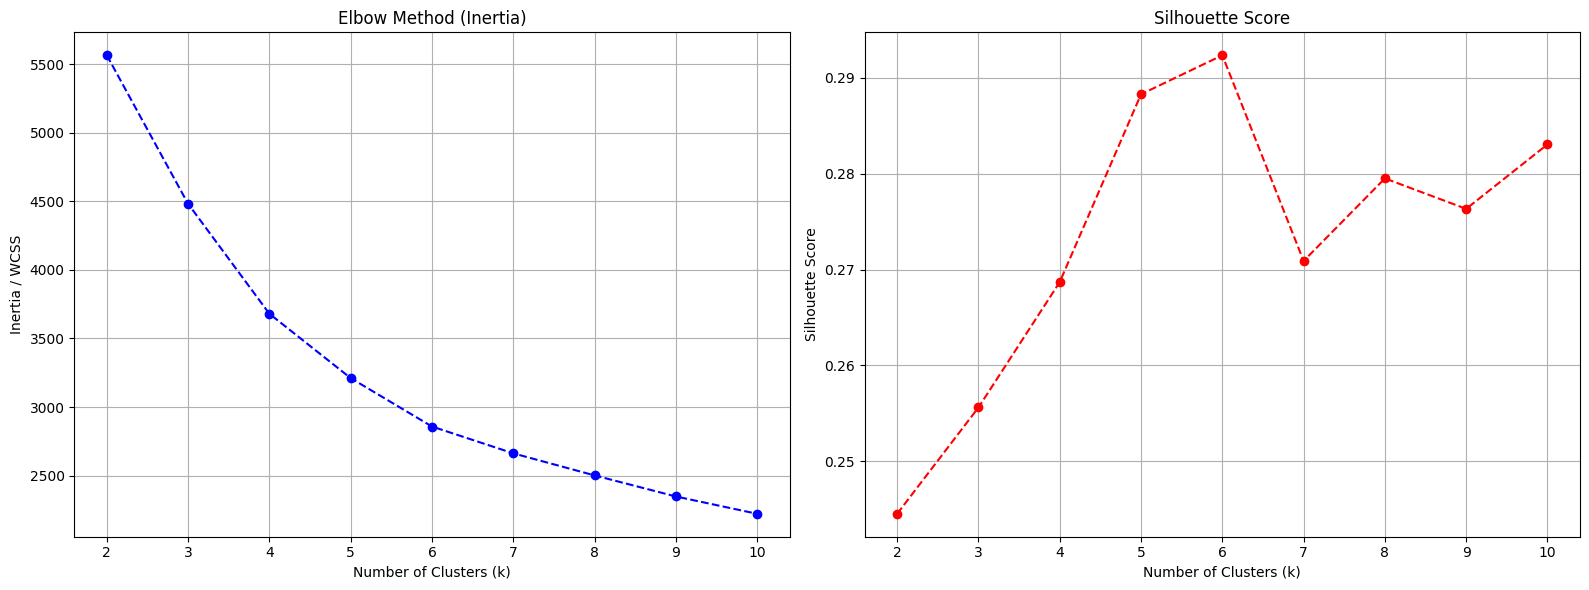

k = 2 | Silhouette Score: 0.2445
k = 3 | Silhouette Score: 0.2556
k = 4 | Silhouette Score: 0.2687
k = 5 | Silhouette Score: 0.2883
k = 6 | Silhouette Score: 0.2924
k = 7 | Silhouette Score: 0.2709
k = 8 | Silhouette Score: 0.2795
k = 9 | Silhouette Score: 0.2763
k = 10 | Silhouette Score: 0.2831


In [5]:
# Menentukan range nilai k yang akan diuji
k_range = range(2, 11)
inertia_list = []
silhouette_scores = []

for k in k_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(df)
    inertia_list.append(kmeans.inertia_)

    score = silhouette_score(df, kmeans.labels_)
    silhouette_scores.append(score)

# Visualisasi Elbow Method dan Silhouette Score secara berdampingan
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# Plot Elbow
ax1.plot(k_range, inertia_list, marker='o', color='b', linestyle='--')
ax1.set_title('Elbow Method (Inertia)')
ax1.set_xlabel('Number of Clusters (k)')
ax1.set_ylabel('Inertia / WCSS')
ax1.grid(True)

# Plot Silhouette
ax2.plot(k_range, silhouette_scores, marker='o', color='r', linestyle='--')
ax2.set_title('Silhouette Score')
ax2.set_xlabel('Number of Clusters (k)')
ax2.set_ylabel('Silhouette Score')
ax2.grid(True)

plt.tight_layout()
plt.show()

# Tampilkan nilai numerik untuk kepastian pemilihan
for k, score in zip(k_range, silhouette_scores):
    print(f"k = {k} | Silhouette Score: {score:.4f}")

### Langkah 3: Menjalankan K-Means dengan Nilai $k$ Terpilih
berdasarkan elbow dan sillhoute membuktikan bahwa k = 5

In [7]:
optimal_k = 5

kmeans_model = KMeans(n_clusters=optimal_k, random_state=42, n_init=10)
clusters = kmeans_model.fit_predict(df)

# Menambahkan hasil label klaster ke dataframe
df_clustered = df.copy()
df_clustered['Cluster'] = clusters

print(f"K-Means berhasil dijalankan dengan k = {optimal_k}")
print(df_clustered['Cluster'].value_counts().sort_index())

K-Means berhasil dijalankan dengan k = 5
Cluster
0    408
1    494
2    208
3    516
4    461
Name: count, dtype: int64


Berdasarkan hasil data, membuktikan bahwa orang dengan riwayat aktivitasnya rendah dan lifestyle nya rendah memiliki data terbanyak

,Cluster,Nama_Cluster
0,0,Pengguna ponsel Pasif
1,1,Gaya Hidup Sehat & Aktif
2,2,Aktif Berolahraga tapi Kurang Sayur
4,3,Kurang Aktif & Minim main ponsel
6,4,Diet Sehat tapi Kurang Aktif


In [10]:
# Menyimpan ulang hasil akhir dengan label Bahasa Indonesia ke file CSV
df_clustered.to_csv(
    '/content/hasil_variandasar.csv',
    index=False
)

print("Berhasil menyimpan file varian dasar dengan nama klaster Bahasa Indonesia!")

Berhasil menyimpan file varian dasar dengan nama klaster Bahasa Indonesia!
